# 07 RQ4 Cross-Commodity Contagion

Synopsis RQ4: energy transport / energy price stress leading agricultural spreads (Granger / VAR; VECM if cointegrated).


In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from project_paths import load_env, ensure_output_dirs
ROOT = load_env()
PATHS = ensure_output_dirs(ROOT)
print("ROOT", ROOT)
print({k: str(v) for k, v in PATHS.items()})

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_squared_error, mean_absolute_error, accuracy_score, f1_score, roc_auc_score, confusion_matrix, RocCurveDisplay
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
sns.set_theme(style="whitegrid", context="talk")
df = pd.read_csv(PATHS["processed"] / "daily_panel_clean.csv", parse_dates=["date"]).sort_values("date").reset_index(drop=True)
print(df.shape)


ROOT /Users/govind/Documents/govind/DBA/QM_640_Analytics_Capstone/github_scaffold
{'root': '/Users/govind/Documents/govind/DBA/QM_640_Analytics_Capstone/github_scaffold', 'raw': '/Users/govind/Documents/govind/DBA/QM_640_Analytics_Capstone/github_scaffold/data/raw', 'processed': '/Users/govind/Documents/govind/DBA/QM_640_Analytics_Capstone/github_scaffold/data/processed', 'outputs': '/Users/govind/Documents/govind/DBA/QM_640_Analytics_Capstone/github_scaffold/notebooks/outputs/latest', 'figures': '/Users/govind/Documents/govind/DBA/QM_640_Analytics_Capstone/github_scaffold/notebooks/outputs/latest/figures', 'tables': '/Users/govind/Documents/govind/DBA/QM_640_Analytics_Capstone/github_scaffold/notebooks/outputs/latest/tables'}


(2066, 21)


In [2]:
from statsmodels.tsa.stattools import adfuller, grangercausalitytests
from statsmodels.tsa.api import VAR

cols = [c for c in ["wti_spot", "wheat", "corn", "grain_calendar_spread", "port_congestion_hours"] if c in df.columns]
work = df[["date"] + cols].dropna().copy()
# Use changes for Granger robustness
work["d_wti"] = work["wti_spot"].pct_change()
work["d_grain"] = work["grain_calendar_spread"].pct_change() if "grain_calendar_spread" in work.columns else work["wheat"].pct_change()
work["d_cong"] = work["port_congestion_hours"].pct_change() if "port_congestion_hours" in work.columns else work["d_wti"]
g = work[["d_cong", "d_grain", "d_wti"]].replace([np.inf, -np.inf], np.nan).dropna()

# ADF
adf_rows = []
for c in g.columns:
    stat, p, *_ = adfuller(g[c].astype(float).values, maxlag=5, autolag=None)
    adf_rows.append({"series": c, "adf_stat": stat, "p_value": p, "stationary_5pct": p < 0.05})
adf_tbl = pd.DataFrame(adf_rows)
adf_tbl.to_csv(PATHS["tables"] / "rq4_adf.csv", index=False)
adf_tbl


/var/folders/fj/xqxzvclj5gb8kwb480n211xr0000gn/T/ipykernel_89684/4034201472.py:15: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, p, *_ = adfuller(g[c].astype(float).values, maxlag=5, autolag=None)
/var/folders/fj/xqxzvclj5gb8kwb480n211xr0000gn/T/ipykernel_89684/4034201472.py:15: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, p, *_ = adfuller(g[c].astype(float).

,series,adf_stat,p_value,stationary_5pct
0,d_cong,-19.626041,0.000000e+00,True
1,d_grain,-18.476745,2.136058e-30,True
2,d_wti,-19.978800,0.000000e+00,True


In [3]:
# Granger: does congestion/energy lead grain?
maxlag = 7
try:
    gc = grangercausalitytests(g[["d_grain", "d_cong"]], maxlag=maxlag, verbose=False)
except TypeError:
    gc = grangercausalitytests(g[["d_grain", "d_cong"]], maxlag=maxlag)
gc_rows = []
for lag, res in gc.items():
    ftest = res[0]["ssr_ftest"]
    gc_rows.append({"direction": "cong->grain", "lag": lag, "F": ftest[0], "p_value": ftest[1]})
try:
    gc2 = grangercausalitytests(g[["d_grain", "d_wti"]], maxlag=maxlag, verbose=False)
except TypeError:
    gc2 = grangercausalitytests(g[["d_grain", "d_wti"]], maxlag=maxlag)
for lag, res in gc2.items():
    ftest = res[0]["ssr_ftest"]
    gc_rows.append({"direction": "wti->grain", "lag": lag, "F": ftest[0], "p_value": ftest[1]})
gc_tbl = pd.DataFrame(gc_rows)
gc_tbl.to_csv(PATHS["tables"] / "rq4_granger.csv", index=False)

# VAR companion forecast (sMAPE on grain changes)
var_data = g[["d_wti", "d_grain"]].dropna().reset_index(drop=True)
split = int(len(var_data) * 0.8)
model = VAR(var_data.iloc[:split]).fit(maxlags=5, ic="aic")
lag_order = max(int(model.k_ar), 1)
if model.k_ar < 1:
    model = VAR(var_data.iloc[:split]).fit(1)
    lag_order = 1
steps = min(30, len(var_data) - split)
forecast = model.forecast(var_data.iloc[split-lag_order:split].values, steps=steps)
actual = var_data.iloc[split:split+len(forecast)]["d_grain"].values
pred = forecast[:, 1]
smape = float(np.mean(2.0 * np.abs(actual - pred) / (np.abs(actual) + np.abs(pred) + 1e-8)) * 100)
metrics = pd.DataFrame([
    {"Model": "Granger+VAR", "Feature Set": "d_wti,d_cong,d_grain", "Validation Approach": "chronological VAR holdout", "Metric 1": gc_tbl.loc[gc_tbl.direction=="wti->grain","p_value"].min(), "Metric 2": smape, "Key Takeaway": "Metric1=min Granger p (wti->grain); Metric2=sMAPE %"}
])
metrics.to_csv(PATHS["outputs"] / "metrics_rq4.csv", index=False)
metrics.to_csv(PATHS["tables"] / "model_performance_rq4.csv", index=False)
print("VAR lag order", lag_order)
display(gc_tbl.sort_values("p_value").head(10))
metrics


VAR lag order 1


,direction,lag,F,p_value
7,wti->grain,1,0.312529,0.576193
0,cong->grain,1,0.169325,0.680756
8,wti->grain,2,0.202756,0.816494
1,cong->grain,2,0.125786,0.881811
9,wti->grain,3,0.153108,0.927719
13,wti->grain,7,0.312894,0.948468
3,cong->grain,4,0.141042,0.966940
2,cong->grain,3,0.083852,0.968858
11,wti->grain,5,0.166234,0.974974
10,wti->grain,4,0.121049,0.975004


,Model,Feature Set,Validation Approach,Metric 1,Metric 2,Key Takeaway
0,Granger+VAR,"d_wti,d_cong,d_grain",chronological VAR holdout,0.576193,199.970762,Metric1=min Granger p (wti->grain); Metric2=sM...


### Figure 7. RQ4 lead-lag style view (energy vs grain changes)


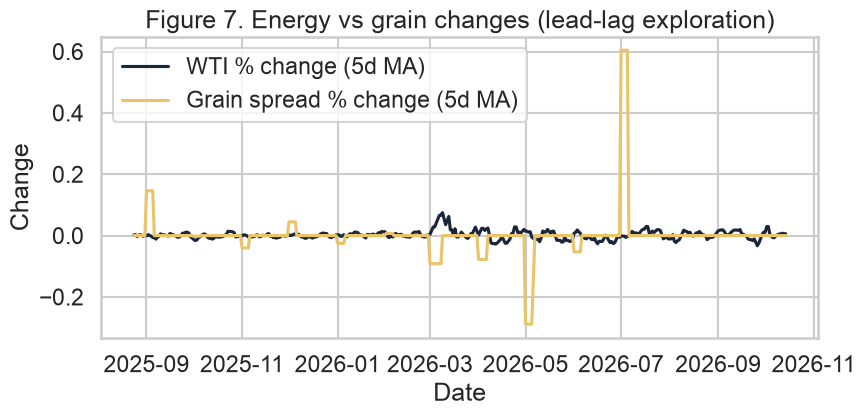

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.5))
plot = work.dropna(subset=["d_wti", "d_grain"]).iloc[-400:]
ax.plot(plot["date"], plot["d_wti"].rolling(5).mean(), label="WTI % change (5d MA)", color="#1b263b")
ax.plot(plot["date"], plot["d_grain"].rolling(5).mean(), label="Grain spread % change (5d MA)", color="#e9c46a")
ax.set_title("Figure 7. Energy vs grain changes (lead-lag exploration)")
ax.set_xlabel("Date")
ax.set_ylabel("Change")
ax.legend()
fig.tight_layout()
fig.savefig(PATHS["figures"] / "fig07_rq4_leadlag.png", dpi=200)
plt.show()


## Next steps after RQ notebooks

1. Review `notebooks/outputs/latest/metrics_rq*.csv` and figures.
2. Append `shared/CHANGELOG.md`.
3. Push `data/` + `notebooks/outputs/` to GitHub (no `.env`).
4. Use outputs to draft the Week4 interim PDF.
